# Contrasting successful transport with failure

## A Generated Design with a Known Modifier

Generated observations are needed because the public panel does not reveal both potential outcomes or a true target effect. Let $G_i\in\{0,1,2,3\}$ be a known effect modifier. The stratum effect is

$$
\tau(g)=0.2+0.4g.
$$

Within each source pair, both members share the same untreated potential outcome. One member is randomly assigned treatment and the other control. Their potential outcomes are

$$
Y_{ig}(0)=m_g+\varepsilon_{ig},\qquad Y_{ig}(1)=Y_{ig}(0)+\tau(g).
$$

Here, $m_g=-0.3+0.25g$ is the stratum baseline, and $\varepsilon_{ig}$ is a generated pair-level disturbance. The paired construction makes the treated-control difference exactly $\tau(g)$ in every source stratum. If $\pi_g^T$ is the generated target share, the known target effect is

$$
\tau^T=\sum_{g=0}^{3}\pi_g^T\tau(g).
$$

The random state is fixed at 6603. The source and target compositions differ by design, so omitting $G_i$ changes the target calculation.

### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("06_transportability");
using CSV, TOML, Printf
using RiskLabAI.CausalFactorAnalysis: transported_ate
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSensitivityStudy.jl"))
include(joinpath("..","support","BookTransportStudy.jl"))
using .BookTransportStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter06_random_inputs"),"transport")
captions=Dict("transport_notation"=>"Notation for finite-stratum transport.","transport_assumption_ledger"=>"Assumption ledger for finite-stratum standardization.","transport_exact_inputs"=>"Inputs for the released exact standardization calculation.","transport_exact_contributions"=>"Stratum contributions to the exact target effect.","transport_exact_check"=>"Exact standardization identity check.","transport_public_provenance"=>"Provenance of the public panel used for descriptive standardization.","transport_public_domains"=>"Source and target domains in the public county calculation.","transport_public_strata"=>"Source outcomes, support counts, and target weights by baseline-employment stratum.","transport_public_support_book"=>"Public support counts and population weights by stratum.","transport_public_contrasts_book"=>"Public source means and contrasts by stratum.","transport_public_effects"=>"Descriptive public source and target comparisons.","transport_public_decomposition"=>"Decomposition of the public source-to-target weight change.","transport_public_decomposition_book"=>"Readable decomposition of the public source-to-target weight change.","transport_public_decomposition_check"=>"Checks for the public weight-shift decomposition.","transport_public_boundaries"=>"Interpretive limits of the public standardization.","support_partition_summary"=>"Support audit as the public baseline partition becomes finer.","support_partition_summary_book"=>"Readable support audit as the public partition becomes finer.","support_primary_terciles"=>"Support audit for the approved three-stratum public calculation.","support_quartile_audit"=>"Four-stratum audit showing the first public support failure.","support_public_failure_record"=>"Recorded failure for the unsupported four-stratum public calculation.","support_target_weight_path"=>"Target-weight path from the public source mix to the public target mix.","support_target_weight_path_selected"=>"Selected points on the public target-weight path.","support_target_weight_path_book"=>"Readable points on the public target-weight path.","support_simplex_extrema"=>"Selected points on the target-weight simplex.","support_zero_mass_contract"=>"Zero-target-mass and positive-target-mass calculations.","support_invalid_input_checks"=>"Explicit input and support failures.","support_invalid_input_checks_book"=>"Plain-language input and support checks.","support_section_summary"=>"Summary of target weights and support checks.","recovery_generated_design"=>"Declared design for the generated transport experiment.","recovery_generated_contract"=>"Scope of the generated transport experiment.","recovery_domain_weights"=>"Generated source and target stratum weights.","recovery_stratum_effects"=>"Known and recovered effects in each generated stratum.","recovery_primary_check"=>"Exact known-truth recovery in the generated design.","recovery_estimate_comparison"=>"Generated estimates under correct, coarsened, and omitted modifiers.","recovery_coarse_strata"=>"Coarsened modifier calculation in the generated design.","recovery_target_mix_path"=>"Generated truth and estimates as the target composition changes.","recovery_target_mix_selected"=>"Selected points on the generated target-composition path.","recovery_target_mix_book"=>"Readable points on the generated target-composition path.","recovery_support_cases"=>"Generated support success and failure cases.","recovery_support_cases_book"=>"Plain-language generated support cases.","recovery_invalid_input_checks"=>"Generated-design input validation checks.","recovery_invalid_input_checks_book"=>"Plain-language generated-design input checks.","recovery_section_summary"=>"Summary of generated recovery and failure results.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim6-"*replace(name,"_"=>"-"))
    return nothing
end;


### Every Generated Stratum Effect Is Recovered Exactly

Row,Parameter,Value
,String,Real
1,Random state,6603
2,Source pairs,1000
3,Source observations,2000
4,Target observations,1500
5,Modifier strata,4
6,Known source effect,0.6
7,Known target effect,1.0


Row,Item,Value
,String,String
1,Reason generated data are necessary,Both potential outcomes and the true target effect must be known
2,Treatment assignment,One randomized treated member and one control member within every source pair
3,Effect modifier,Four-level observed stratum
4,Generated market claim,None
5,Download during execution,None


Row,Stratum,Source probability,Target probability,True stratum effect
,Int64,Float64,Float64,Float64
1,0,0.4,0.1,0.2
2,1,0.3,0.2,0.6
3,2,0.2,0.3,1.0
4,3,0.1,0.4,1.4


Row,Stratum,Source control count,Source treated count,True effect,Recovered effect,Recovery error
,Int64,Int64,Int64,Float64,Float64,Float64
1,0,400,400,0.2,0.2,-2.77556e-17
2,1,300,300,0.6,0.6,0.0
3,2,200,200,1.0,1.0,-1.11022e-16
4,3,100,100,1.4,1.4,2.22045e-16


Row,Quantity,Value
,String,Float64
1,Known target effect,1.0
2,Transported estimate,1.0
3,Recovery error,0.0


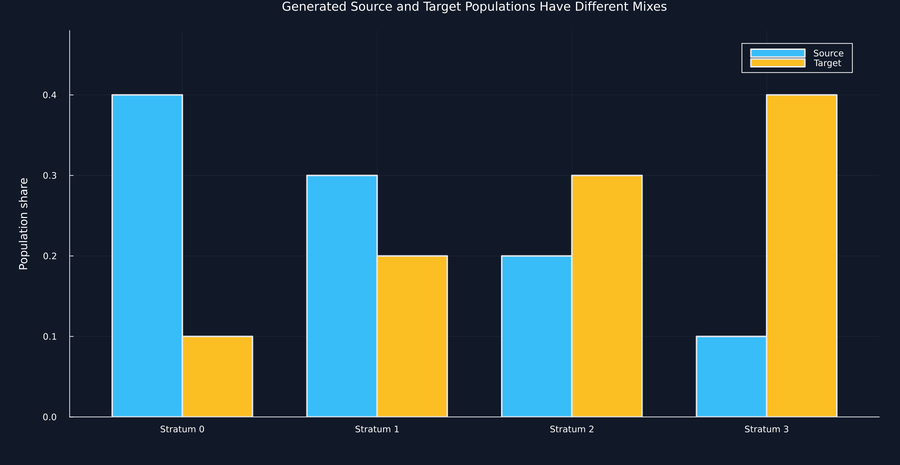

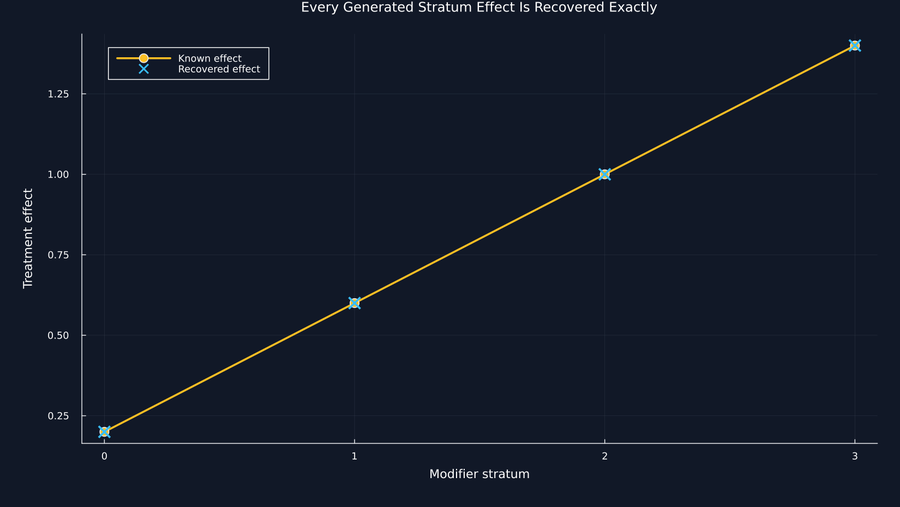

In [1]:
random_state=6603
source_pair_counts=[400,300,200,100]
target_counts=[150,300,450,600]
strata=collect(0:3)
source_generated,target_generated,true_effects=generated_transport(store)
save_data(source_generated,paths,"recovery_source_generated")
save_data(target_generated,paths,"recovery_target_generated")
source_means=[mean(source_generated[(source_generated.Stratum.==stratum).&(source_generated.Treatment.==treatment),"Observed outcome"]) for stratum in strata,treatment in 0:1]
source_counts=[count((source_generated.Stratum.==stratum).&(source_generated.Treatment.==treatment)) for stratum in strata,treatment in 0:1]
target_probabilities=[count(==(stratum),target_generated.Stratum)/nrow(target_generated) for stratum in strata]
source_probabilities=[count(==(stratum),source_generated.Stratum)/nrow(source_generated) for stratum in strata]
recovered_effects=source_means[:,2]-source_means[:,1]
transported=transported_ate(source_means[:,2],source_means[:,1],target_probabilities,source_counts[:,2],source_counts[:,1])
known_target_effect=dot(target_probabilities,true_effects)
known_source_effect=dot(source_probabilities,true_effects)
@assert all(isapprox.(recovered_effects,true_effects))
@assert isapprox(transported,known_target_effect)
design=frame(["Parameter","Value"],[("Random state",random_state),("Source pairs",sum(source_pair_counts)),("Source observations",nrow(source_generated)),("Target observations",nrow(target_generated)),("Modifier strata",length(strata)),("Known source effect",known_source_effect),("Known target effect",known_target_effect)])
table(design,"recovery_generated_design")
generated_contract = frame(["Item","Value"],[["Reason generated data are necessary","Both potential outcomes and the true target effect must be known"],["Treatment assignment","One randomized treated member and one control member within every source pair"],["Effect modifier","Four-level observed stratum"],["Generated market claim","None"],["Download during execution","None"]])
table(generated_contract,"recovery_generated_contract")
weight_table=DataFrame("Stratum"=>strata,"Source probability"=>source_probabilities,"Target probability"=>target_probabilities,"True stratum effect"=>true_effects)
table(weight_table,"recovery_domain_weights")
stratum_recovery=DataFrame("Stratum"=>strata,"Source control count"=>source_counts[:,1],"Source treated count"=>source_counts[:,2],"True effect"=>true_effects,"Recovered effect"=>recovered_effects,"Recovery error"=>recovered_effects-true_effects)
table(stratum_recovery,"recovery_stratum_effects")
primary_recovery=frame(["Quantity","Value"],[("Known target effect",known_target_effect),("Transported estimate",transported),("Recovery error",transported-known_target_effect)])
table(primary_recovery,"recovery_primary_check")
save_data(weight_table,paths,"recovery_domain_weights")
figure=paired_bars("Stratum ".*string.(strata),source_probabilities,target_probabilities,"Generated Source and Target Populations Have Different Mixes","Population share";size=(1200,620))
save_figure(figure,paths,"recovery_domain_weights")
save_data(stratum_recovery,paths,"recovery_stratum_effects")
figure=plot(strata,true_effects;color=palette.amber,marker=:circle,markersize=6,linewidth=2.4,label="Known effect",xlabel="Modifier stratum",ylabel="Treatment effect",xticks=strata,title="Every Generated Stratum Effect Is Recovered Exactly",size=(1100,620),legend=:topleft)
scatter!(figure,strata,recovered_effects;color=palette.cyan,marker=:xcross,markersize=7,markerstrokewidth=2,label="Recovered effect")
save_figure(figure,paths,"recovery_stratum_effects")


## How an omitted modifier changes the target mix

If the modifier is omitted, the calculation uses the source mixture of stratum effects. In this design that value is

$$
\tau^{S}=\sum_{g=0}^{3}\pi_g^S\tau(g),
$$

where $\pi_g^S$ is the source probability of stratum $g$. The true target value instead uses $\pi_g^T$. Their difference is specific to the declared design; it is not a general direction of bias.

A coarsened modifier combines adjacent strata. The source effect within each combined group then depends on the source composition inside that group. If the target has a different internal composition, coarse standardization need not recover the target truth.

Row,Calculation,Estimate,Error from target truth
,String,Float64,Float64
1,Known target effect,1.0,0.0
2,Four-stratum transport,1.0,0.0
3,Two-stratum coarse transport,0.904762,-0.0952381
4,Modifier omitted,0.6,-0.4
5,Known source effect,0.6,-0.4


Row,Coarse stratum,Source control count,Source treated count,Source contrast,Target probability
,Int64,Int64,Int64,Float64,Float64
1,0,700,700,0.371429,0.3
2,1,300,300,1.13333,0.7


Row,Target mixing weight,Known effect,Four-stratum estimate,Two-stratum estimate,Omitted-modifier estimate,Four-stratum error,Two-stratum error,Omitted-modifier error
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0,0.6,0.6,0.6,0.6,-1.11022e-16,0.0,1.11022e-16
2,0.05,0.62,0.62,0.615238,0.6,-1.11022e-16,-0.0047619,-0.02
3,0.1,0.64,0.64,0.630476,0.6,0.0,-0.00952381,-0.04
4,0.15,0.66,0.66,0.645714,0.6,0.0,-0.0142857,-0.06
5,0.2,0.68,0.68,0.660952,0.6,0.0,-0.0190476,-0.08
6,0.25,0.7,0.7,0.67619,0.6,-1.11022e-16,-0.0238095,-0.1
7,0.3,0.72,0.72,0.691429,0.6,0.0,-0.0285714,-0.12
8,0.35,0.74,0.74,0.706667,0.6,0.0,-0.0333333,-0.14
9,0.4,0.76,0.76,0.721905,0.6,0.0,-0.0380952,-0.16


Row,Target mixing weight,Known effect,Four-stratum estimate,Two-stratum estimate,Omitted-modifier estimate,Four-stratum error,Two-stratum error,Omitted-modifier error
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0,0.6,0.6,0.6,0.6,-1.11022e-16,0.0,1.11022e-16
2,0.25,0.7,0.7,0.67619,0.6,-1.11022e-16,-0.0238095,-0.1
3,0.5,0.8,0.8,0.752381,0.6,0.0,-0.047619,-0.2
4,0.75,0.9,0.9,0.828571,0.6,0.0,-0.0714286,-0.3
5,1.0,1.0,1.0,0.904762,0.6,0.0,-0.0952381,-0.4


Row,Mix,Known effect,Four strata,Two strata,Modifier omitted
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.6,0.6,0.6,0.6
2,0.25,0.7,0.7,0.67619,0.6
3,0.5,0.8,0.8,0.752381,0.6
4,0.75,0.9,0.9,0.828571,0.6
5,1.0,1.0,1.0,0.904762,0.6


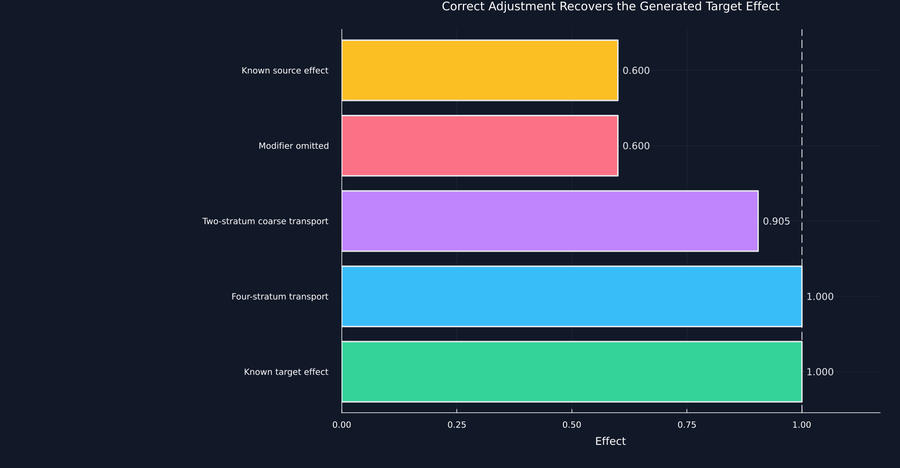

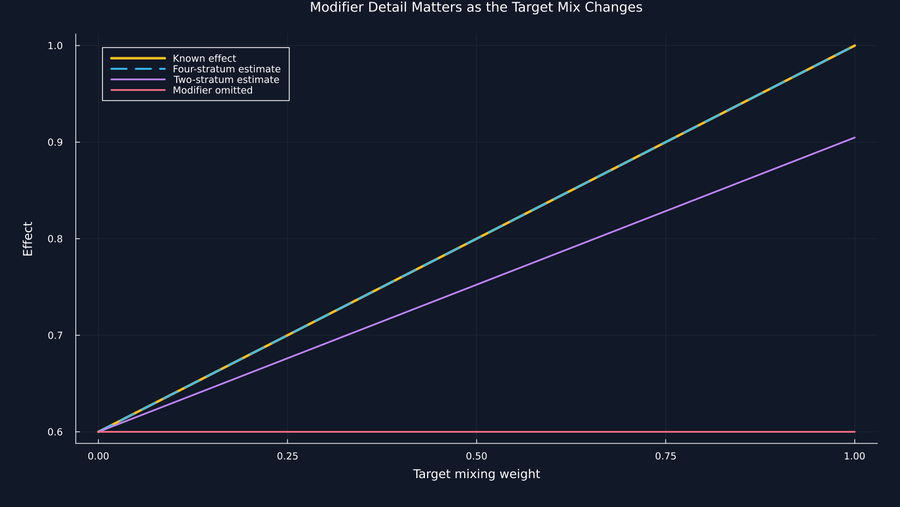

In [2]:
omitted_modifier=transported_ate([mean(source_generated[source_generated.Treatment.==1,"Observed outcome"])],[mean(source_generated[source_generated.Treatment.==0,"Observed outcome"])],[1.],[count(==(1),source_generated.Treatment)],[count(==(0),source_generated.Treatment)])
source_generated[!,"Coarse stratum"]=Int.(source_generated.Stratum.>=2)
target_generated[!,"Coarse stratum"]=Int.(target_generated.Stratum.>=2)
coarse_means=[mean(source_generated[(source_generated[:,"Coarse stratum"].==stratum).&(source_generated.Treatment.==treatment),"Observed outcome"]) for stratum in 0:1,treatment in 0:1]
coarse_counts=[count((source_generated[:,"Coarse stratum"].==stratum).&(source_generated.Treatment.==treatment)) for stratum in 0:1,treatment in 0:1]
coarse_target_probabilities=[count(==(stratum),target_generated[:,"Coarse stratum"])/nrow(target_generated) for stratum in 0:1]
coarse_transport=transported_ate(coarse_means[:,2],coarse_means[:,1],coarse_target_probabilities,coarse_counts[:,2],coarse_counts[:,1])
comparison=frame(["Calculation","Estimate","Error from target truth"],[("Known target effect",known_target_effect,0.),("Four-stratum transport",transported,transported-known_target_effect),("Two-stratum coarse transport",coarse_transport,coarse_transport-known_target_effect),("Modifier omitted",omitted_modifier,omitted_modifier-known_target_effect),("Known source effect",known_source_effect,known_source_effect-known_target_effect)])
table(comparison,"recovery_estimate_comparison")
coarse_details=DataFrame("Coarse stratum"=>0:1,"Source control count"=>coarse_counts[:,1],"Source treated count"=>coarse_counts[:,2],"Source contrast"=>coarse_means[:,2]-coarse_means[:,1],"Target probability"=>coarse_target_probabilities)
table(coarse_details,"recovery_coarse_strata")
mix_rows=[]
for mix in range(0.,1.;length=21)
    weights=(1-mix).*source_probabilities+mix.*target_probabilities
    truth=dot(weights,true_effects)
    coarse_weights=[sum(weights[1:2]),sum(weights[3:4])]
    coarse_value=dot(coarse_weights,coarse_means[:,2]-coarse_means[:,1])
    push!(mix_rows,(mix,truth,dot(weights,recovered_effects),coarse_value,omitted_modifier))
end
mix_path=frame(["Target mixing weight","Known effect","Four-stratum estimate","Two-stratum estimate","Omitted-modifier estimate"],mix_rows)
mix_path[!,"Four-stratum error"]=mix_path[:,3]-mix_path[:,2]
mix_path[!,"Two-stratum error"]=mix_path[:,4]-mix_path[:,2]
mix_path[!,"Omitted-modifier error"]=mix_path[:,5]-mix_path[:,2]
table(mix_path,"recovery_target_mix_path")
table(mix_path[[1,6,11,16,21],:],"recovery_target_mix_selected")
mix_path_book=rename(mix_path[[1,6,11,16,21],1:5],["Mix","Known effect","Four strata","Two strata","Modifier omitted"])
table(mix_path_book,"recovery_target_mix_book")
save_data(comparison,paths,"recovery_estimate_comparison")
figure=bar(1:5,comparison[:,2];orientation=:h,color=[palette.green,palette.cyan,"#C084FC",palette.rose,palette.amber],yticks=(1:5,comparison[:,1]),xlabel="Effect",title="Correct Adjustment Recovers the Generated Target Effect",legend=false,xlims=(0,1.17maximum(comparison[:,2])),size=(1250,650),left_margin=70Plots.mm)
vline!(figure,[known_target_effect];color=palette.text,linestyle=:dash,linewidth=1.2,label="")
for (index,value) in enumerate(comparison[:,2])
    annotate!(figure,value+.04,index,text(@sprintf("%.3f",value),9,palette.text))
end
save_figure(figure,paths,"recovery_estimate_comparison")
save_data(mix_path,paths,"recovery_target_mix_path")
figure=plot(mix_path[:,1],mix_path[:,2];color=palette.amber,linewidth=3,label="Known effect",xlabel="Target mixing weight",ylabel="Effect",title="Modifier Detail Matters as the Target Mix Changes",size=(1100,620),legend=:topleft)
plot!(figure,mix_path[:,1],mix_path[:,3];color=palette.cyan,linestyle=:dash,linewidth=2.3,label="Four-stratum estimate")
plot!(figure,mix_path[:,1],mix_path[:,4];color="#C084FC",linewidth=2.1,label="Two-stratum estimate")
plot!(figure,mix_path[:,1],mix_path[:,5];color=palette.rose,linewidth=2.1,label="Modifier omitted")
save_figure(figure,paths,"recovery_target_mix_path")


## Detecting missing support during validation

For the generated four-stratum design, remove treated source support from the highest stratum while retaining positive target mass. The support condition fails because

$$
\pi_3^T>0\quad\text{and}\quad n_{1,3}^S=0.
$$

Here, stratum $3$ is target relevant, but its treated source count is zero. The calculation must stop rather than fill the missing conditional mean by extrapolation. If the target weight of stratum $3$ is changed to zero, the supported remaining strata can still be standardized.

Row,Case,Result,Value,Message
,String,String,Float64,String
1,Complete four-stratum support,Pass,1.0,Calculated
2,Missing treated support with positive target mass,Stop,NaN,ArgumentError: target-positive strata lack source treatment support
3,Missing treated support with zero target mass,Pass,0.733333,Unsupported stratum contributes zero


Row,Case,Result,Value
,String,String,Float64
1,Both source groups appear in every target stratum,Calculated,1.0
2,Treated source group is missing where the target has mass,Stopped,NaN
3,Treated source group is missing where target mass is zero,Calculated,0.733333


Row,Check,Rejected,Message
,String,String,String
1,Probabilities do not sum to one,Pass,ArgumentError: target_probabilities must sum to one along its last dimension
2,Negative treated count,Pass,ArgumentError: stratum arrays must match with nonnegative source counts
3,Mismatched mean arrays,Pass,ArgumentError: stratum arrays must match with nonnegative source counts
4,Nonfinite control mean,Pass,ArgumentError: control_means must contain finite values


Row,Check,Result
,String,String
1,Weights sum to one,Stopped as required
2,Source counts are nonnegative,Stopped as required
3,All mean lists have equal length,Stopped as required
4,All supplied means are finite,Stopped as required


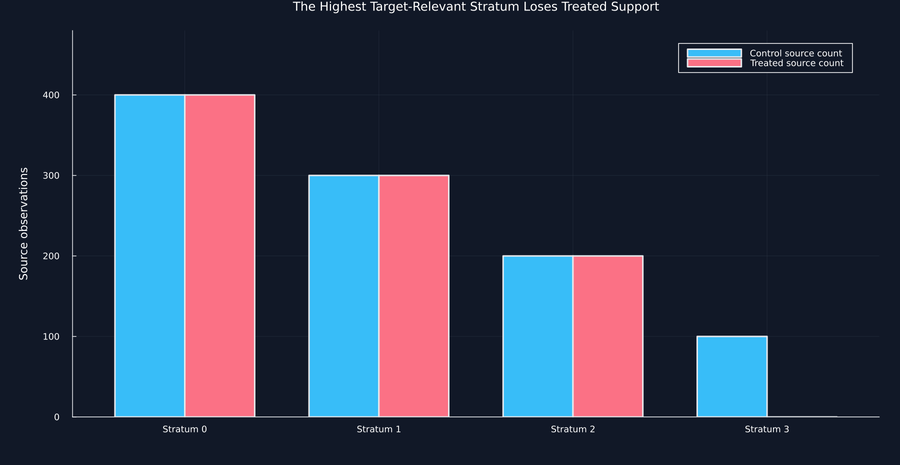

Row,Result,Value
,String,String
1,Four-stratum recovery,Exact in the declared paired design
2,Two-stratum coarsening,Misses target truth because internal mixes differ
3,Modifier omitted,"Returns the source mixture, not the target mixture"
4,Missing target-positive support,Calculation stops explicitly
5,Generality,All numerical directions are local to the declared design


In [3]:
missing_treated_counts=Float64.(source_counts[:,2])
missing_treated_counts[end]=0.
control_counts=Float64.(source_counts[:,1])
support_failure=transport_failure("Positive target mass with missing treated support",()->transported_ate(source_means[:,2],source_means[:,1],target_probabilities,missing_treated_counts,control_counts))
zero_high_weight=copy(target_probabilities)
zero_high_weight[end]=0.
zero_high_weight./=sum(zero_high_weight)
zero_high_value=transported_ate(source_means[:,2],source_means[:,1],zero_high_weight,missing_treated_counts,control_counts)
support_cases=frame(["Case","Result","Value","Message"],[("Complete four-stratum support","Pass",transported,"Calculated"),("Missing treated support with positive target mass","Stop",NaN,support_failure[3]),("Missing treated support with zero target mass","Pass",zero_high_value,"Unsupported stratum contributes zero")])
table(support_cases,"recovery_support_cases")
support_cases_book=frame(["Case","Result","Value"],[("Both source groups appear in every target stratum","Calculated",transported),("Treated source group is missing where the target has mass","Stopped",NaN),("Treated source group is missing where target mass is zero","Calculated",zero_high_value)])
table(support_cases_book,"recovery_support_cases_book")
@assert support_failure[2]
invalid_checks=frame(["Check","Rejected","Message"],[transport_failure("Probabilities do not sum to one",()->transported_ate([1,2],[0,0],[.4,.5],[1,1],[1,1])),transport_failure("Negative treated count",()->transported_ate([1],[0],[1],[-1],[1])),transport_failure("Mismatched mean arrays",()->transported_ate([1,2],[0],[.5,.5],[1,1],[1,1])),transport_failure("Nonfinite control mean",()->transported_ate([1,2],[0,Inf],[1,0],[1,0],[1,0]))])
table(invalid_checks,"recovery_invalid_input_checks")
invalid_checks_book = frame(["Check","Result"],[["Weights sum to one","Stopped as required"],["Source counts are nonnegative","Stopped as required"],["All mean lists have equal length","Stopped as required"],["All supplied means are finite","Stopped as required"]])
table(invalid_checks_book,"recovery_invalid_input_checks_book")
@assert all(invalid_checks.Rejected)
support_plot=DataFrame("Stratum"=>strata,"Control count"=>control_counts,"Treated count after removal"=>missing_treated_counts,"Target probability"=>target_probabilities)
save_data(support_plot,paths,"recovery_support_failure")
figure=paired_bars("Stratum ".*string.(strata),support_plot[:,2],support_plot[:,3],"The Highest Target-Relevant Stratum Loses Treated Support","Source observations";left_label="Control source count",right_label="Treated source count",right_color=palette.rose,size=(1200,620))
save_figure(figure,paths,"recovery_support_failure")
recovery_summary = frame(["Result","Value"],[["Four-stratum recovery","Exact in the declared paired design"],["Two-stratum coarsening","Misses target truth because internal mixes differ"],["Modifier omitted","Returns the source mixture, not the target mixture"],["Missing target-positive support","Calculation stops explicitly"],["Generality","All numerical directions are local to the declared design"]])
table(recovery_summary,"recovery_section_summary")
